# 00 · A common yardstick for "pure", "mixed" and "disentangled" codes

**Project 2 — When does the brain mix and when does it disentangle? Energy, statistics, task demands and single-neuron computation**

Mixed selectivity (Rigotti et al. 2013; Fusi, Miller & Rigotti 2016) and disentanglement
(Whittington et al. 2023) are usually measured with different tools in different literatures.
Before any experiment we validate one set of metrics on hand-built codes with known ground truth:

| level | metric | meaning |
|---|---|---|
| neuron | **class** (pure / linear-mixed / nonlinear-mixed) | does a neuron depend on 1 factor, on several additively, or on their interaction? |
| neuron | **NMS index** = (R²full − R²additive)/R²full | how much of a neuron's explainable variance needs interaction terms |
| population | **disentanglement** (variance-based modularity) | 1 = each neuron's variance comes from a single factor |
| population | participation ratio | linear dimensionality |
| population | **shattering dimensionality** (SD) | fraction of random dichotomies linearly decodable — the *benefit* of mixing |
| population | **CCGP** | cross-condition generalisation — abstraction, the *benefit* of factorisation |
| population | energy | mean rate, mean squared rate |

Key point to keep in mind for the paper: **disentangled ≠ pure** in general (a neuron can be
pure in a linear-mixed population basis) and **NMS ↑ ⇒ SD ↑ but CCGP ↓** (Bernardi et al. 2020).

In [1]:
import os, sys, json, time
import numpy as np
import torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
from mixdis import data, models, metrics, dendrite, rnn
from mixdis.utils import save_json, load_json, set_threads

# FAST=1 -> tiny smoke-test run (minutes). Unset/0 -> full experiment.
FAST = os.environ.get("FAST", "0") == "1"
set_threads()
RES = os.path.abspath("../results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(RES, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
def savefig(name):
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", dpi=200)
    plt.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
print("FAST mode:", FAST, "| torch", torch.__version__, "| threads", torch.get_num_threads())

FAST mode: False | torch 2.14.1 | threads 7


## 1. Continuous factors

In [2]:
rng = np.random.default_rng(0)
n, K, N = 3000, 2, 20
F = rng.uniform(-1, 1, (n, K)).astype(np.float32)
W = rng.normal(0, 1, (K, N)); b = rng.uniform(-0.5, 0.5, N)
k = rng.integers(0, K, N); sgn = rng.choice([-1, 1], N)
C = rng.uniform(-1, 1, (N, K))
codes = {
    "pure (rectified, 1 factor/neuron)": np.maximum(0, sgn * F[:, k] + b),
    "linear mixed (no rectification)": F @ W,
    "rectified random mixing (lazy-like)": np.maximum(0, F @ W + b),
    "multiplicative (f1·f2 terms)": F[:, [0]] * F[:, [1]] * rng.normal(0, 1, N) + 0.2 * F @ W,
    "conjunctive bumps (place-cell-like)": np.exp(-((F[:, None, :] - C[None]) ** 2).sum(-1) / 0.2),
}
rows = {}
for nm, Z in codes.items():
    s = metrics.summary_continuous(Z, F)
    rows[nm] = s
    print(f"{nm:38s} disent {s['disent']:.2f} | NMS {s['nms_mean']:.2f} | pure {s['pure']:.2f} lin {s['linear_mixed']:.2f} "
          f"nonlin {s['nonlinear_mixed']:.2f} | PR {s['pr']:.1f}")

pure (rectified, 1 factor/neuron)      disent 1.00 | NMS 0.00 | pure 1.00 lin 0.00 nonlin 0.00 | PR 2.4
linear mixed (no rectification)        disent 0.53 | NMS 0.00 | pure 0.35 lin 0.65 nonlin 0.00 | PR 1.6
rectified random mixing (lazy-like)    disent 0.55 | NMS 0.13 | pure 0.25 lin 0.25 nonlin 0.50 | PR 2.2
multiplicative (f1·f2 terms)           disent 0.63 | NMS 0.58 | pure 0.05 lin 0.20 nonlin 0.75 | PR 1.7
conjunctive bumps (place-cell-like)    disent 0.20 | NMS 0.26 | pure 0.00 lin 0.10 nonlin 0.90 | PR 6.4


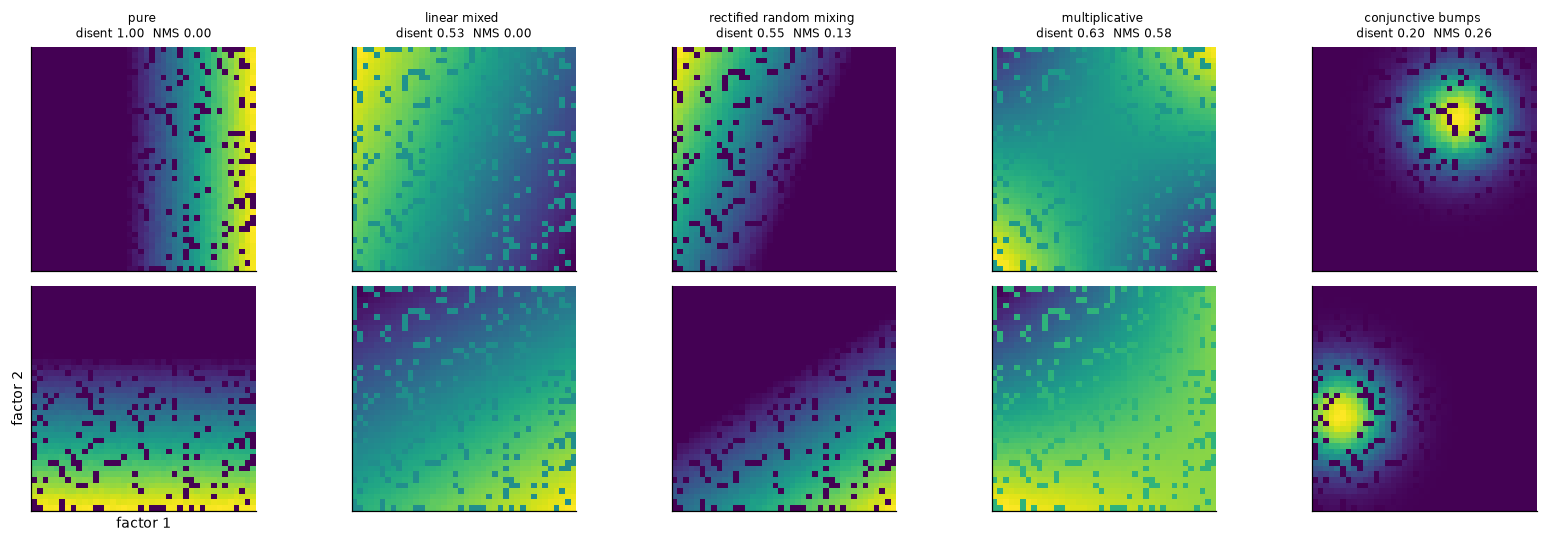

In [3]:
fig, axs = plt.subplots(2, len(codes), figsize=(3 * len(codes), 5))
g = np.linspace(-1, 1, 40); GG = np.stack(np.meshgrid(g, g), -1).reshape(-1, 2)
for j, (nm, Z) in enumerate(codes.items()):
    # tuning surface of the first two neurons, by nearest-neighbour binning
    for r in range(2):
        i = r
        H = np.zeros((40, 40)); Cn = np.zeros((40, 40))
        ix = np.clip(((F + 1) / 2 * 39).round().astype(int), 0, 39)
        np.add.at(H, (ix[:, 1], ix[:, 0]), Z[:, i]); np.add.at(Cn, (ix[:, 1], ix[:, 0]), 1)
        axs[r, j].imshow(H / np.maximum(Cn, 1), origin="lower", extent=[-1, 1, -1, 1], cmap="viridis")
        axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
    axs[0, j].set_title(nm.split("(")[0] + f"\ndisent {rows[nm]['disent']:.2f}  NMS {rows[nm]['nms_mean']:.2f}", fontsize=8)
axs[1, 0].set_xlabel("factor 1"); axs[1, 0].set_ylabel("factor 2")
plt.tight_layout(); savefig("00_metric_validation_continuous"); plt.show()

**Result.** The metrics separate the reference codes as intended:

| code | disentanglement | NMS index | nonlinear-mixed fraction | PR |
|---|---|---|---|---|
| pure (rectified, one factor per neuron) | 1.00 | 0.00 | 0.00 | 2.4 |
| linear mixed | 0.53 | 0.00 | 0.00 | 1.6 |
| rectified random mixing | 0.55 | 0.13 | 0.50 | 2.2 |
| multiplicative | 0.63 | 0.58 | 0.75 | 1.7 |
| conjunctive bumps | 0.20 | 0.26 | 0.90 | 6.4 |

Two cautions carried into every later notebook: (i) rectification alone creates measurable nonlinear mixing (0.50 of neurons
in a random ReLU code), so a ReLU network is never "purely linear-mixed"; (ii) disentanglement and NMS measure different
things — the multiplicative code is fairly modular (0.63) yet strongly nonlinear.

## 2. Discrete factors: the shattering vs abstraction trade-off

pure             SD 0.75 | CCGP 1.00 | NMS 0.00 | nonlinear-mixed frac 0.00
linear mixed     SD 0.76 | CCGP 1.00 | NMS 0.00 | nonlinear-mixed frac 0.00
random (NMS)     SD 1.00 | CCGP 0.35 | NMS 0.59 | nonlinear-mixed frac 0.96
XOR-conjunctive  SD 0.68 | CCGP 0.17 | NMS 1.00 | nonlinear-mixed frac 1.00


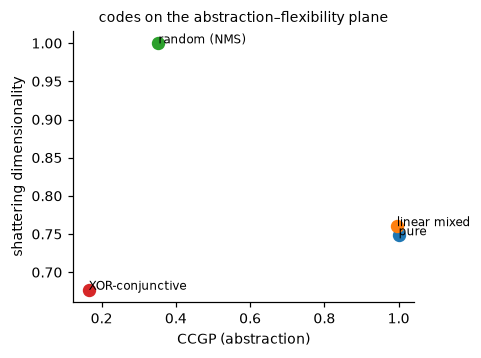

In [4]:
lev = (2, 2, 2); conds = data.discrete_conditions(lev); Cn = len(conds)
rngd = np.random.default_rng(1)
proto = {
    "pure": np.concatenate([np.eye(2)[conds[:, k]] for k in range(3)], 1).repeat(4, 1),
    "linear mixed": np.concatenate([np.eye(2)[conds[:, k]] for k in range(3)], 1) @ rngd.normal(0, 1, (6, 24)),
    "random (NMS)": rngd.normal(0, 1, (Cn, 24)),
    "XOR-conjunctive": np.stack([(conds[:, 0] ^ conds[:, 1]), (conds[:, 1] ^ conds[:, 2]), conds[:, 0] ^ conds[:, 2]], 1).repeat(8, 1).astype(float),
}
reps = 50; disc = {}
for nm, P in proto.items():
    idx = np.repeat(np.arange(Cn), reps)
    Z = P[idx] + 0.3 * rngd.normal(size=(len(idx), P.shape[1]))
    cls, nms, _ = metrics.selectivity_discrete(Z, conds[idx])
    fr = metrics.class_fractions(cls)
    sd = metrics.shattering_dim(Z, idx, n_dich=30)
    cg = np.nanmean([metrics.ccgp(Z, conds[idx], k) for k in range(3)])
    disc[nm] = dict(SD=sd, CCGP=cg, NMS=float(np.nanmean(nms)), **fr)
    print(f"{nm:16s} SD {sd:.2f} | CCGP {cg:.2f} | NMS {np.nanmean(nms):.2f} | nonlinear-mixed frac {fr['nonlinear_mixed']:.2f}")
plt.figure(figsize=(4, 3.2))
for nm, d in disc.items():
    plt.scatter(d["CCGP"], d["SD"], s=60); plt.annotate(nm, (d["CCGP"], d["SD"]), fontsize=8)
plt.xlabel("CCGP (abstraction)"); plt.ylabel("shattering dimensionality"); plt.title("codes on the abstraction–flexibility plane", fontsize=9)
savefig("00_sd_vs_ccgp"); plt.show()
save_json({"continuous": rows, "discrete": disc}, os.path.join(RES, "nb00_metrics_validation.json"))

**Result.** On discrete factors the classic trade-off appears: pure and linear-mixed codes have perfect abstraction (CCGP = 1.00)
but limited flexibility (SD 0.75–0.76); random nonlinear mixing gives full flexibility (SD = 1.00) and poor abstraction
(CCGP = 0.35); an XOR-conjunctive code has NMS = 1.00 but low SD (0.68) and CCGP (0.17) because it encodes only three conjunctions.
The notebooks that follow place trained networks on these same axes.